In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score, adjusted_rand_score, rand_score
from sklearn.feature_extraction import text
from sklearn.decomposition import PCA


<h2>File reading</h2>

In [2]:
n_clusters=2
n_init=1

data = pd.read_csv("data_unsupervised.csv", encoding="utf8")[0:1000]
data=data.dropna() #drop empty rows
data.drop_duplicates()#drop duplicates

vectorizer = text.CountVectorizer(
    max_df=0.95,
    stop_words='english')
counts = vectorizer.fit_transform(data['body'])
vectorizedData = text.TfidfTransformer().fit_transform(counts)

<h2>KMeans</h2>

<h3>Determining the number of clusters</h3>

In [3]:
def plot_clustering_error_and_silhouette(clustering_data):
    fig, axs = plt.subplots(1,2, figsize=(8, 3.5))

    axs[0].plot(
        [k for k in k_values], 
        [result.inertia_ for result in clustering_data]
    )
    axs[0].set_xlabel("Number of clusters k")
    axs[0].set_ylabel("Clustering error")
    axs[0].grid()

    axs[1].plot(
        [k for k in k_values], 
        [silhouette_score(vectorizedData, result.labels_) for result in clustering_data]
    )
    axs[1].set_xlabel("Number of clusters k")
    axs[1].set_ylabel("Silhouette")#Compute the mean Silhouette Coefficient of all samples.
    """
    the silhouette coefficient is a measure of how similar an object is to other object in its own cluster compared to other clusters.
    We're considering the mean silhouette coefficient of all samples in the dataset.
    A high value indicates that the samples are well clustered, while a low value indicates that the samples are not well clustered.
    0 indicates that the cluster might be overlapping (or are very close) -> TODO change hyperparameters to get a better result
    """
    axs[1].grid()

    plt.tight_layout()
    plt.show()

Trying to use "k-means++" as init instead of random initialization
centroids are equally spaced -> probably better results than random initialization
also it should converge faster

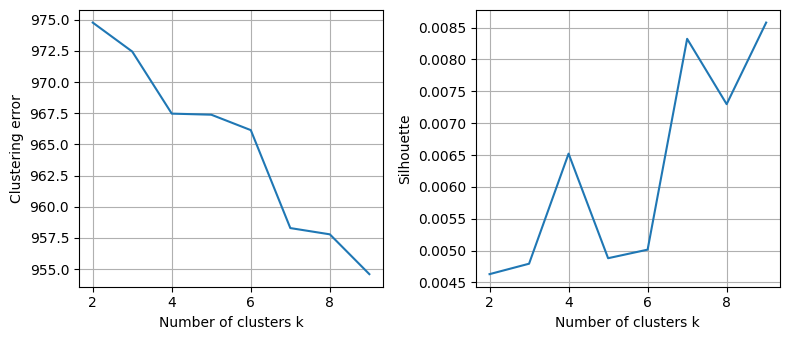

In [13]:
kmeans = KMeans(
    n_clusters, #will be choosen later
    #init='random', #centroids are initialized randomly TOO SLOW
    init='k-means++', #centroids are equally spaced -> probably better than random initialization. and should converge faster
    random_state=None, 
    n_init='auto', #number of times the k-means algorithm will be run with different centroid seeds. 'auto' uses a default value based on init
    max_iter=300
    )
kmeans_results = []
k_values=pd.Series(range(2, 10, 1))#this will need to be changed
for k in k_values:
    kmeans_results.append(KMeans(n_clusters=k).fit(vectorizedData))

plot_clustering_error_and_silhouette(kmeans_results)

Now we're trying to see what happens when the number of clusters gets closer to the number of subreddits

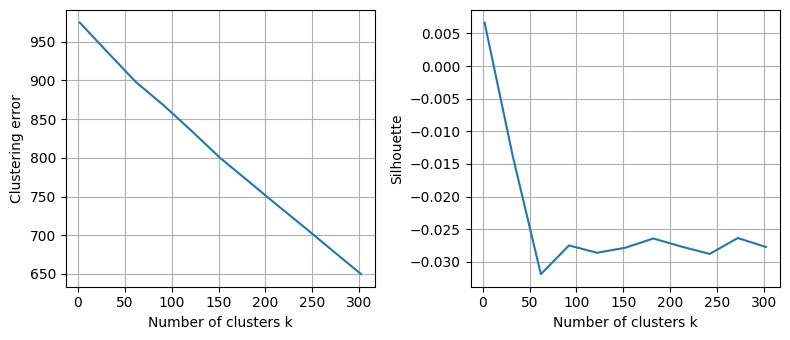

In [17]:
number_of_subreddits = data.subreddit.unique().shape[0]

kmeans = KMeans(
    n_clusters, #will be choosen later
    init='k-means++', 
    random_state=None, 
    n_init='auto', #number of times the k-means algorithm will be run with different centroid seeds. 'auto' uses a default value based on init
    max_iter=300
    )
kmeans_results = []
k_values=pd.Series(range(2, number_of_subreddits, 30))#this will need to be changed
for k in k_values:
    kmeans_results.append(KMeans(n_clusters=k).fit(vectorizedData))

plot_clustering_error_and_silhouette(kmeans_results)

<h3>DBscan</h3>

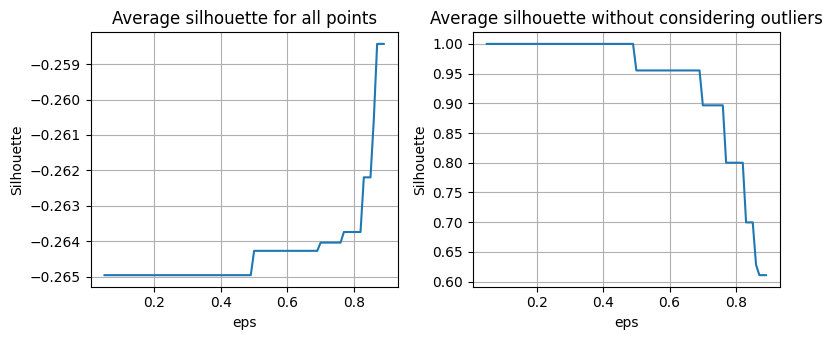

In [6]:
from sklearn.cluster import DBSCAN

dbscan_results = []
for eps in np.arange(0.05, 0.9, 0.01): #from 0.05 to 0.9 with steps of 0.1
    dbscan_tmp = DBSCAN(eps=eps, min_samples=3)
    dbscan_tmp.fit(vectorizedData)
    dbscan_results.append((eps, dbscan_tmp))

silhouettes_dbscan = []
silhouettes_dbscan_noOutliers= []

for eps, dbscan_result in dbscan_results:

    # compute silhouette score
    #print(dbscan_result.labels_)
    if dbscan_result.labels_.max() > 0:
        score = silhouette_score(vectorizedData, dbscan_result.labels_)
        silhouettes_dbscan.append((eps, score))

    # compute silhouette score only of clustered samples (not noise, i.e., not -1)
    mask = dbscan_result.labels_ != -1
    score = silhouette_score(
        #vectorizedData[~vectorizedData.index.isin(np.where(dbscan_result.labels_ == -1)[0])],
        vectorizedData[mask,:],
        np.delete(dbscan_result.labels_, np.where(dbscan_result.labels_ == -1))
    )
    silhouettes_dbscan_noOutliers.append((eps, score))


fig, axs = plt.subplots(1,2, figsize=(8, 3.5))

axs[0].plot(
    [eps for (eps, _) in silhouettes_dbscan], 
    [score for (_, score) in silhouettes_dbscan] 
)
axs[0].set_xlabel("eps")
axs[0].set_ylabel("Silhouette")
axs[0].set_title("Average silhouette for all points")
axs[0].grid()

axs[1].plot(
    [eps for (eps, _) in silhouettes_dbscan_noOutliers], 
    [score for (_, score) in silhouettes_dbscan_noOutliers] 
)
axs[1].set_xlabel("eps")
axs[1].set_ylabel("Silhouette")
axs[1].set_title("Average silhouette without considering outliers")
axs[1].grid()

#axs[1].axis('off')  # Hide the second subplot since we are not using
plt.tight_layout()
plt.show()


<h3>User Distribution Analysis</h3>
<h4>ECDF</h4>
TODO: controllare se sta roba ha senso

None


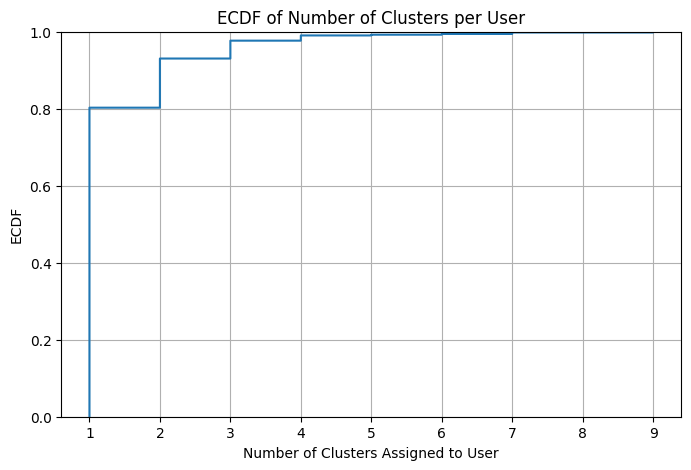

In [7]:
#print(kmeans_results[1].labels_)
indexOfChoosenCluster=7
print(data.insert(loc=1,column="cluster",value=kmeans_results[indexOfChoosenCluster].labels_))

user_clusters = data.groupby('author')['cluster'].nunique().reset_index()
user_clusters.columns = ['author', 'num_clusters']

# Step 2: Plot ECDF
plt.figure(figsize=(8, 5))
sns.ecdfplot(data=user_clusters, x='num_clusters')
plt.xlabel('Number of Clusters Assigned to User')
plt.ylabel('ECDF')
plt.title('ECDF of Number of Clusters per User')
plt.grid(True)
plt.show()

Use the first two components of the PCA (found in Section 1.4). Then visualize on these two dimensions to gain insights into their distribution and separability.

In [18]:
#Read the components from PCA.csv
#pca = pd.read_csv("PCA.csv", encoding="utf8").iloc[:,1:3]
#print(pca)

"""
#TODO change the number of clusters
kmeans = KMeans(n_clusters=8, random_state=0)
cl_labels = kmeans.fit_predict(pca)

# Step 3: Create projection DataFrame
projection = pd.DataFrame(pca, columns=['PC1', 'PC2'])
projection['cidBest'] = [f'C{x}' for x in cl_labels]
projection['label'] = y.reshape(-1)

# Step 4: Plotting
fig, axs = plt.subplots(3, 1, figsize=(6, 10))

for i in np.unique(projection.cid3):
    subdf = projection[projection.cid3 == i]
    axs[0].scatter(subdf['PC1'], subdf['PC2'], label=i, s=5)
axs[0].grid()
axs[0].legend(bbox_to_anchor=(1, 1), loc="upper left")
axs[0].set_xlabel('PC1')
axs[0].set_ylabel('PC2')
axs[0].set_title('k-Means with k=3')

for i in np.unique(projection.cidBest):
    subdf = projection[projection.cidBest == i]
    axs[1].scatter(subdf['PC1'], subdf['PC2'], label=i, s=5)
axs[1].grid()
axs[1].legend(bbox_to_anchor=(1, 1), loc="upper left")
axs[1].set_xlabel('PC1')
axs[1].set_ylabel('PC2')
axs[1].set_title(f'k-Means with K={best_n}')

for i in np.unique(y):
    subdf = projection[projection.label == i]
    axs[2].scatter(subdf['PC1'], subdf['PC2'], label=i, s=5)
axs[2].grid()
axs[2].legend(bbox_to_anchor=(1, 1), loc="upper left")
axs[2].set_xlabel('PC1')
axs[2].set_ylabel('PC2')
axs[2].set_title('GT Labels')

plt.tight_layout()
plt.show()
"""

'\n#TODO change the number of clusters\nkmeans = KMeans(n_clusters=8, random_state=0)\ncl_labels = kmeans.fit_predict(pca)\n\n# Step 3: Create projection DataFrame\nprojection = pd.DataFrame(pca, columns=[\'PC1\', \'PC2\'])\nprojection[\'cidBest\'] = [f\'C{x}\' for x in cl_labels]\nprojection[\'label\'] = y.reshape(-1)\n\n# Step 4: Plotting\nfig, axs = plt.subplots(3, 1, figsize=(6, 10))\n\nfor i in np.unique(projection.cid3):\n    subdf = projection[projection.cid3 == i]\n    axs[0].scatter(subdf[\'PC1\'], subdf[\'PC2\'], label=i, s=5)\naxs[0].grid()\naxs[0].legend(bbox_to_anchor=(1, 1), loc="upper left")\naxs[0].set_xlabel(\'PC1\')\naxs[0].set_ylabel(\'PC2\')\naxs[0].set_title(\'k-Means with k=3\')\n\nfor i in np.unique(projection.cidBest):\n    subdf = projection[projection.cidBest == i]\n    axs[1].scatter(subdf[\'PC1\'], subdf[\'PC2\'], label=i, s=5)\naxs[1].grid()\naxs[1].legend(bbox_to_anchor=(1, 1), loc="upper left")\naxs[1].set_xlabel(\'PC1\')\naxs[1].set_ylabel(\'PC2\')\naxs[